# LGND API Demo — October 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EarthLegend/developer_resources/blob/main/demo/03-api-demo-october-2026/LGND_API_Demo_October_2026.ipynb)

This notebook walks through the [LGND Embeddings API](https://embeddings.api.lgnd.ai/v1/reference) on NAIP aerial imagery of California:

1. **Search by text** — find burn scars with a plain-language query
2. **Chip thumbnails and metadata** — look at the imagery behind each result
3. **Change detection** — find places that changed from farmland to homes
4. **Change description** — have the API explain what changed in plain language

## Before you start

1. Go to **[developer.lgnd.ai](https://developer.lgnd.ai)** and create an account.
2. Create an **API key** (it starts with `sk_`).
3. Your account comes with an indexed **NAIP collection**. Find it in the portal and copy its **collection ID** (it starts with `col_`).

## Add your credentials

**Google Colab:** click the key icon (🔑 *Secrets*) in the left sidebar and add:

| Name | Value |
|---|---|
| `LGND_API_KEY` | your API key (`sk_...`) |
| `LGND_COLLECTION_ID` | your collection ID (`col_...`) |

Turn on *Notebook access* for both.

**Your own computer:** run `cp ../../.env.example .env` from this notebook's folder and fill in the same two values.

If you skip both, the setup cell will ask you to paste them in. You can also paste your collection ID straight into the setup cell.

In [ ]:
# Installs the packages this notebook needs (Colab already has most of them)
%pip install -q requests folium python-dotenv

## Setup

This cell loads your credentials and finds the tenant (your LGND account) that owns your collection.

In [2]:
import os
from getpass import getpass
from IPython.display import display, Image
import requests
import folium
from dotenv import load_dotenv

load_dotenv()  # reads .env when running locally

# Paste your collection ID from developer.lgnd.ai here, or set LGND_COLLECTION_ID
COLLECTION_ID = ""

BASE_URL       = "https://embeddings.api.lgnd.ai/v1"
CHIPS_BASE_URL = f"{BASE_URL}/chips"


def get_setting(name, secret=False):
    """Read a setting from Colab Secrets, then environment variables / .env, then ask for it."""
    try:
        from google.colab import userdata
        try:
            value = userdata.get(name)
            if value:
                return value.strip()
        except Exception:
            pass  # secret not set, or notebook access not granted
    except ImportError:
        pass  # not running in Colab
    value = os.environ.get(name)
    if value:
        return value.strip()
    prompt = f"Paste your {name}: "
    return (getpass(prompt) if secret else input(prompt)).strip()


API_KEY       = get_setting("LGND_API_KEY", secret=True)
COLLECTION_ID = COLLECTION_ID.strip() or get_setting("LGND_COLLECTION_ID")

headers = {"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}

# Find which of your tenants owns this collection
resp = requests.get(f"{BASE_URL}/tenants", headers=headers)
if resp.status_code == 401:
    raise RuntimeError("Your API key was rejected. Check LGND_API_KEY (it should start with sk_).")
resp.raise_for_status()

TENANT_ID = None
for tenant in resp.json()["data"]:
    r = requests.get(f"{BASE_URL}/tenants/{tenant['id']}/collections/{COLLECTION_ID}", headers=headers)
    if r.ok:
        TENANT_ID, collection = tenant["id"], r.json()
        break

if TENANT_ID is None:
    raise RuntimeError(
        f"Collection {COLLECTION_ID!r} isn't visible to this API key. "
        "Copy the collection ID from your account at developer.lgnd.ai."
    )

print(f"Using collection {collection.get('name')} ({COLLECTION_ID})")
print(f"  status: {collection.get('status')}  dates: {collection.get('start_date')} → {collection.get('end_date')}")

Using collection California NAIP 2020-2022 (col_019d078b0e437f8a9410dd36fe355bdf)
  status: READY  dates: 2020-01-01 → 2022-12-31


## Search by Text

LGND's `search-by-text` endpoint converts a natural-language query into an embedding and returns the most visually similar chips in the collection ranked by cosine similarity. Results are plotted as orange polygons on an interactive satellite basemap centered on California.

In [3]:
# LGND's search-by-text endpoint embeds the query string and finds the most visually
# similar satellite image chips in the collection using cosine similarity.
response = requests.post(
    f"{BASE_URL}/tenants/{TENANT_ID}/collections/{COLLECTION_ID}/search-by-text",
    headers=headers,
    json={"query": "burn scar", "top_k": 100}
)
response.raise_for_status()
search_results = response.json()
print(f"Found {len(search_results['data'])} results")

# Fetch California boundary for the map overlay
california_geojson = requests.get(
    "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/USA/CA.geo.json"
).json()

# Each result includes a chip geometry — a small geographic tile of satellite imagery —
# along with a similarity score. We plot these as orange polygons on a satellite basemap.
m = folium.Map(location=[36.7783, -119.4179], zoom_start=8, tiles="Esri WorldImagery")

folium.GeoJson(california_geojson, name="California",
               style_function=lambda x: {"color": "black", "weight": 1}).add_to(m)

for result in search_results["data"]:
    if result.get("geometry", {}).get("type") == "Polygon":
        folium.GeoJson(
            result["geometry"],
            tooltip=f"Score: {result['score']:.2f}  |  {result.get('collection')}  |  {result.get('datetime', '')[:10]}",
            style_function=lambda x: {"fillColor": "#FFA500", "color": "orange", "weight": 2, "fillOpacity": 0.6},
        ).add_to(m)

folium.LayerControl().add_to(m)
display(m)

Found 100 results


## Chip Thumbnails

Each chip exposes a `/thumbnail` endpoint that returns a JPEG preview of the satellite imagery at that location. This cell fetches and displays the top 3 results from the text search above.

Fetching thumbnails for 3 chips...



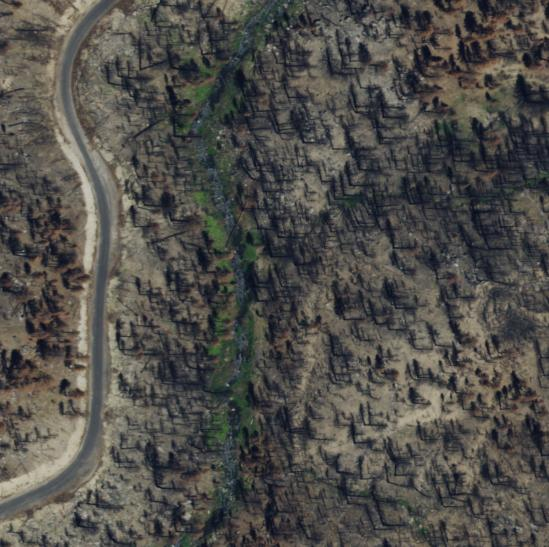

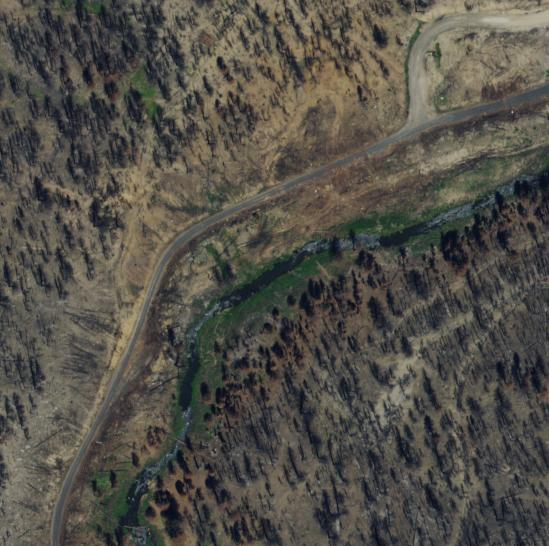

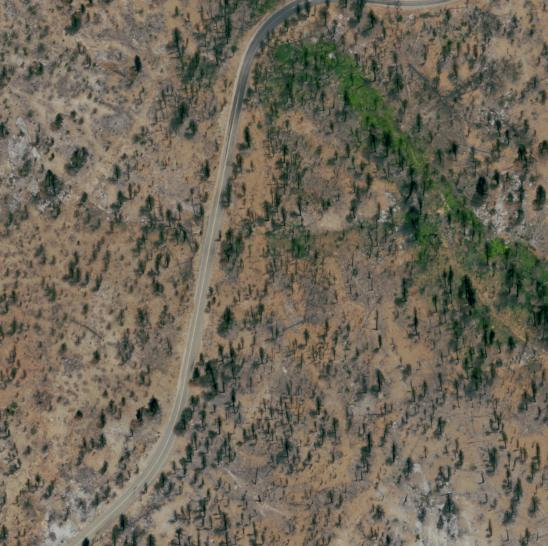

In [4]:
MAX_THUMBNAILS = 3

chip_ids = [r['chip_id'] for r in search_results.get('data', [])][:MAX_THUMBNAILS]
print(f"Fetching thumbnails for {len(chip_ids)} chips...\n")

for chip_id in chip_ids:
    resp = requests.get(f"{CHIPS_BASE_URL}/{chip_id}/thumbnail", headers=headers)
    if resp.status_code == 200:
        display(Image(data=resp.content))
    else:
        print(f"Failed {chip_id}: {resp.status_code}")

## Chip Metadata

The `/chips/{chip_id}` endpoint returns structured metadata for a chip: collection name, capture date, geographic bounding box, and the path to the source raster asset. This is useful for understanding the imagery that underlies each search result.

In [5]:
for chip_id in chip_ids:
    resp = requests.get(f"{CHIPS_BASE_URL}/{chip_id}", headers=headers)
    if resp.status_code == 200:
        data = resp.json()
        print(f"=== {chip_id} ===")
        print(f"  Collection:      {data.get('collection')}")
        print(f"  Date:            {data.get('datetime')}")
        print(f"  Chip size (m):   {data.get('chip_size_m')}")
        print(f"  Raster ID:       {data.get('raster_id')}")
        print(f"  Factory version: {data.get('factory_version')}")
        geom = data.get('geometry', {})
        coords = geom.get('coordinates', [[]])[0]
        if coords:
            lons = [c[0] for c in coords]
            lats = [c[1] for c in coords]
            print(f"  Bounding box:    lon [{min(lons):.6f}, {max(lons):.6f}]  lat [{min(lats):.6f}, {max(lats):.6f}]")
    else:
        print(f"Failed {chip_id}: {resp.status_code}")

=== chip_9b5a9bd5de06910363d5cd6dec3d65ce ===
  Collection:      naip
  Date:            2020-07-11T00:00:00Z
  Chip size (m):   320
  Raster ID:       raster_467e7d59dc012a2200f5479f5f7286e5
  Factory version: None
  Bounding box:    lon [-120.632740, -120.628981]  lat [40.114664, 40.117538]


=== chip_8c30e383bed8234861e16755b5a3379a ===
  Collection:      naip
  Date:            2020-07-11T00:00:00Z
  Chip size (m):   320
  Raster ID:       raster_467e7d59dc012a2200f5479f5f7286e5
  Factory version: None
  Bounding box:    lon [-120.647694, -120.643935]  lat [40.106040, 40.108914]


=== chip_db57c9124b5c79b5dc475642f7c6d8ce ===
  Collection:      naip
  Date:            2022-08-03T00:00:00Z
  Chip size (m):   320
  Raster ID:       raster_2b93f0d4cff89dc7a989bf5572e727c5
  Factory version: None
  Bounding box:    lon [-119.375389, -119.371772]  lat [37.378070, 37.380945]


## Change Detection

LGND's `search-changes-by-text` endpoint finds chips whose embeddings shifted in a direction you define — described here in plain text as land transitioning from farmland to homes, searched across all of California. The API returns `changed_chip_pair` objects, each containing a `chip_past` and `chip_current` with their own chip IDs, scores, and geometries.

{'data': [{'object': 'changed_chip_pair', 'chip_past': {'chip_id': 'chip_d9c7c67979eb12b1498a0d9f6da9bd99', 'score': 0.12063530019943071, 'geometry': {'coordinates': [[[-120.106739159, 36.969880865], [-120.106739159, 36.972755438], [-120.110337108, 36.972755438], [-120.110337108, 36.969880865], [-120.106739159, 36.969880865]]], 'type': 'Polygon'}, 'raster_id': 'raster_d8de9d4901faeca330fe198b8bb8c2b2', 'datetime': '2020-06-16 00:00:00', 'collection': 'naip'}, 'chip_current': {'chip_id': 'chip_f9c58a725a2c53f136d01ff6fee9c3b4', 'score': 0.2968289653591058, 'geometry': {'coordinates': [[[-120.106739159, 36.969880865], [-120.106739159, 36.972755438], [-120.110337108, 36.972755438], [-120.110337108, 36.969880865], [-120.106739159, 36.969880865]]], 'type': 'Polygon'}, 'raster_id': 'raster_07f6a50e3e8bfd67a7cacdc854001b6b', 'datetime': '2022-06-15 00:00:00', 'collection': 'naip'}, 'cell_id': 'cell_7ade72c649d6c9bccd9791b7efc48799', 'score': 0.20873213277926825, 'score_past': 0.12063530019943

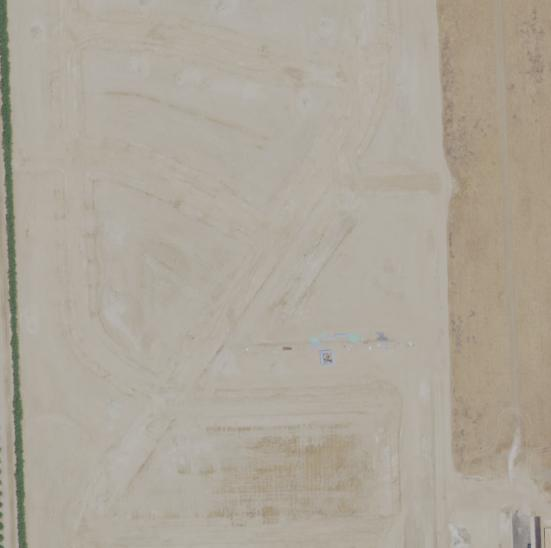

After


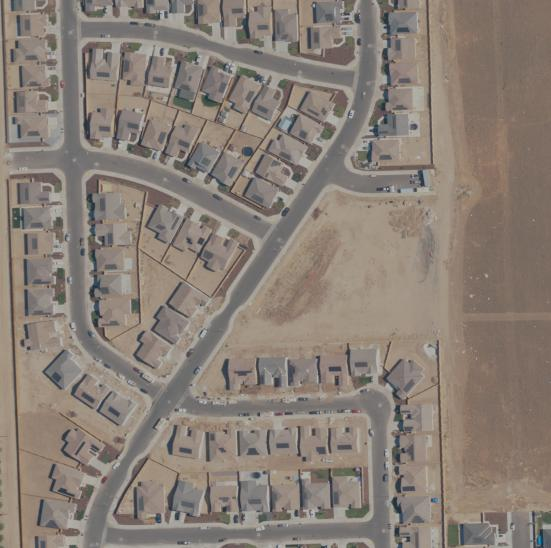

Before


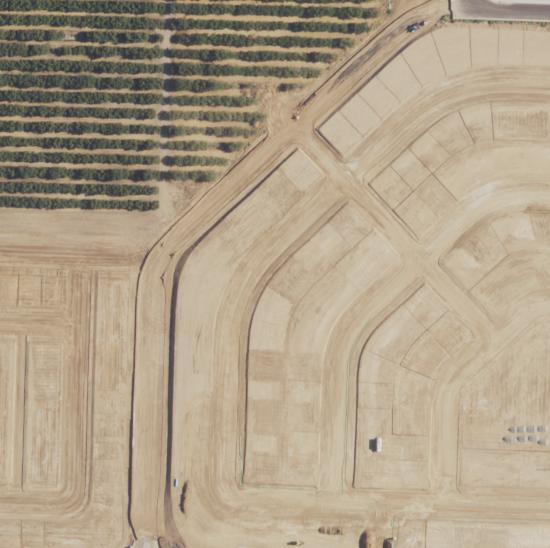

After


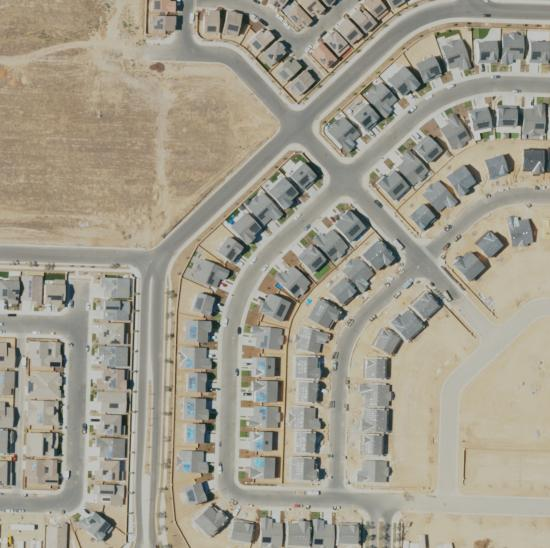

Before


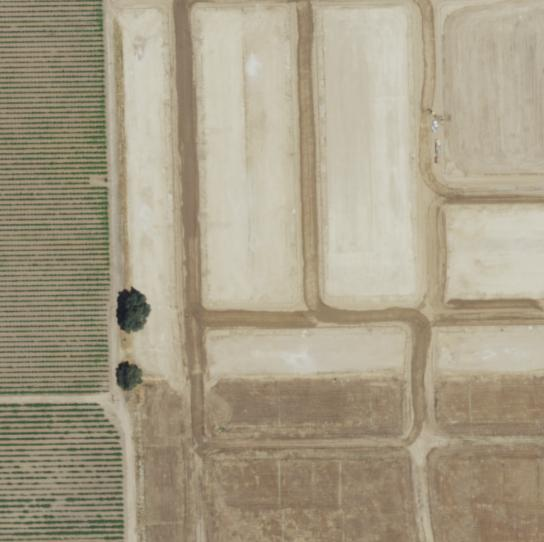

After


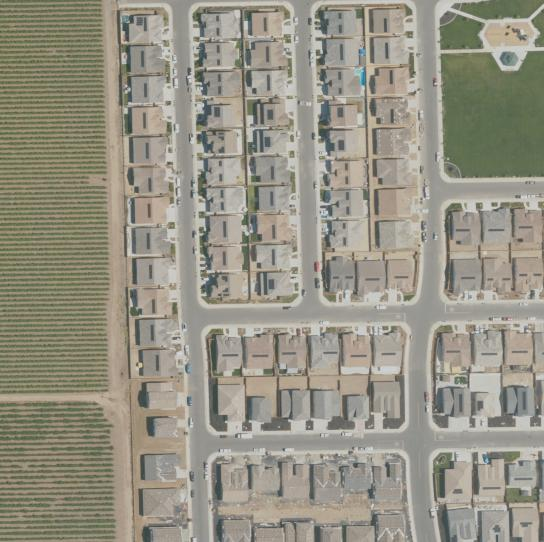

In [6]:
CHANGE_DETECTION_URL = f"{BASE_URL}/tenants/{TENANT_ID}/collections/{COLLECTION_ID}/search-changes-by-text"


# Search across the whole state of California, using the boundary polygon fetched above
payload = {
    "geometry": california_geojson["features"][0]["geometry"],
    "before":"farm",
    "after":"homes",
    "top_k": 3
}

resp = requests.post(CHANGE_DETECTION_URL, headers=headers, json=payload)
print(resp.json())
resp.raise_for_status()
changed_chips = resp.json()

# Each result is a changed_chip_pair with chip_past and chip_current
print(f"Found {len(changed_chips.get('data', []))} changed chip pairs\n")
for pair in changed_chips.get('data', []):
    print(f"  past:    {pair['chip_past']['chip_id']}  (score {pair['chip_past']['score']:.4f})")
    print(f"  current: {pair['chip_current']['chip_id']}  (score {pair['chip_current']['score']:.4f})")
    print()

# Display before/after thumbnails for the top-scoring pair
if changed_chips.get('data'):
    for chip in changed_chips['data']:
        for label, chip_id in [("Before", chip['chip_past']['chip_id']), ("After", chip['chip_current']['chip_id'])]:
            print(label)
            thumb_resp = requests.get(f"{CHIPS_BASE_URL}/{chip_id}/thumbnail", headers=headers)
            if thumb_resp.status_code == 200:
                display(Image(data=thumb_resp.content))

## Change Description

LGND's `change-description-by-chip-pairs` endpoint takes 1–50 same-cell `(chip_past_id, chip_current_id)` pairs and returns a plain-language description of what changed. A single pair yields a localized description of that cell; multiple pairs yield a regional summary. `verbosity` can be `"detailed"` (default) or `"concise"` (faster).

Before (2020-06-16)


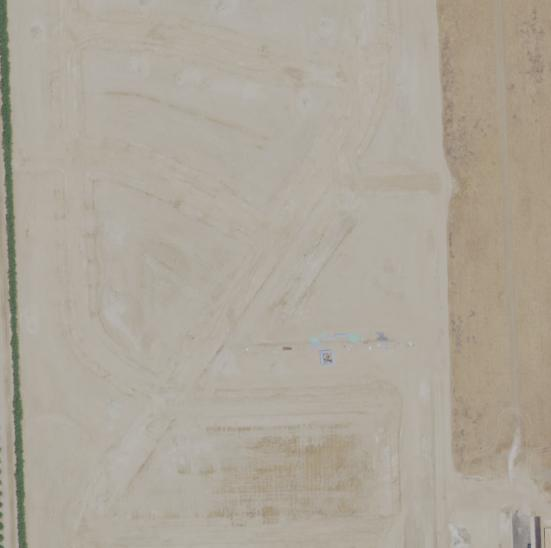

After (2022-06-15)


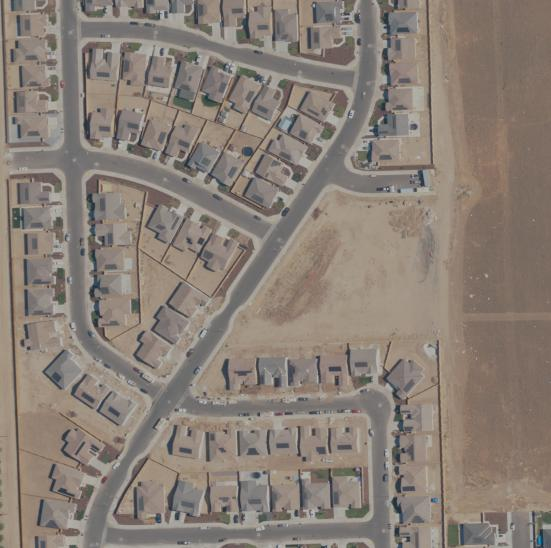

**Summary:** Extensive residential development has transformed previously cleared land into a dense housing area with new roads and infrastructure.

**Key changes:**
- **New structures** (throughout): A large-scale residential development comprising numerous houses has been constructed across the top, left, and central portions of the former cleared land.
- **Removed structures** (centre-right): The small, light-colored temporary structures or equipment visible in Image 1 have been removed.
- **New roads/tracks** (throughout): An extensive network of paved residential roads and driveways has been established to serve the new housing development.
- **Land use change** (throughout): The area has transitioned from cleared, undeveloped land (likely prepared for construction) to a thriving residential subdivision.


In [7]:
CHANGE_DESCRIPTION_URL = f"{BASE_URL}/tenants/{TENANT_ID}/collections/{COLLECTION_ID}/change-description-by-chip-pairs"

# Take the top-scoring pair from the change detection results above
if not changed_chips.get("data"):
    raise RuntimeError("Change detection found no pairs. Try different before/after text and re-run the cell above.")
top_pair = changed_chips["data"][0]

resp = requests.post(CHANGE_DESCRIPTION_URL, headers=headers, json={
    "pairs": [{
        "chip_past_id": top_pair["chip_past"]["chip_id"],
        "chip_current_id": top_pair["chip_current"]["chip_id"],
    }],
    "verbosity": "detailed",
})
resp.raise_for_status()
description = resp.json()

for label, chip in [("Before", top_pair["chip_past"]), ("After", top_pair["chip_current"])]:
    print(f"{label} ({chip['datetime'][:10]})")
    thumb_resp = requests.get(f"{CHIPS_BASE_URL}/{chip['chip_id']}/thumbnail", headers=headers)
    if thumb_resp.status_code == 200:
        display(Image(data=thumb_resp.content))

print(description["description"])